In [43]:
import os
import requests

In [44]:
# read the data and store the text

file_path = "the-verdict.txt"

with open(file_path, "r", encoding = "utf-8") as f:
    raw_text = f.read()

In [45]:
len(raw_text)

20479

### simple tokenization with regular expressions
Example text = "Hello, I am Abhishek Sharma. I am a software engineer."
token = ['Hello', ',', 'I', 'am', 'Abhishek', 'Sharma', '.', 'I', 'am', 'a', 'software', 'engineer', '.']

![Screenshot 2026-08-29 222631.png](<attachment:Screenshot 2026-08-29 222631.png>)
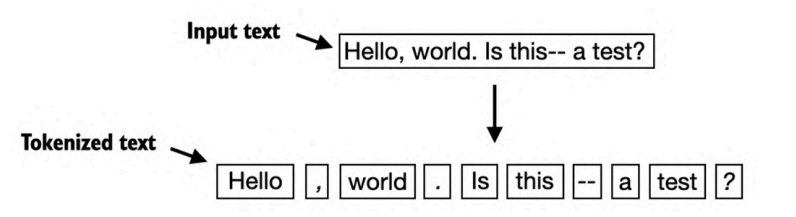

In [46]:
import re

text = "Hello, I am Abhishek Sharma. I am a software engineer."
result = re.split(r'(\s)', text)

print(result)

['Hello,', ' ', 'I', ' ', 'am', ' ', 'Abhishek', ' ', 'Sharma.', ' ', 'I', ' ', 'am', ' ', 'a', ' ', 'software', ' ', 'engineer.']


In [47]:
result = re.split(r'([,.]|\s)', text)

print(result)

['Hello', ',', '', ' ', 'I', ' ', 'am', ' ', 'Abhishek', ' ', 'Sharma', '.', '', ' ', 'I', ' ', 'am', ' ', 'a', ' ', 'software', ' ', 'engineer', '.', '']


In [48]:
result = [item for item in result if item.strip()]
print(result)

['Hello', ',', 'I', 'am', 'Abhishek', 'Sharma', '.', 'I', 'am', 'a', 'software', 'engineer', '.']


In [49]:
text = "Hello, world. Is this-- a test?"

result = re.split(r'([,.:;?_!"()\']|--|\s)', text)
result = [item.strip() for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


In [50]:
# applying this simple tokenization in our raw_text

preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
print(preprocessed[:30])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


In [51]:
print(len(preprocessed))

4690


### Converting tokens to token IDs

Example: 
token: ['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']

ids: [1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 18, 9]

![Screenshot 2026-08-29 230152.png](<attachment:Screenshot 2026-08-29 230152.png>)
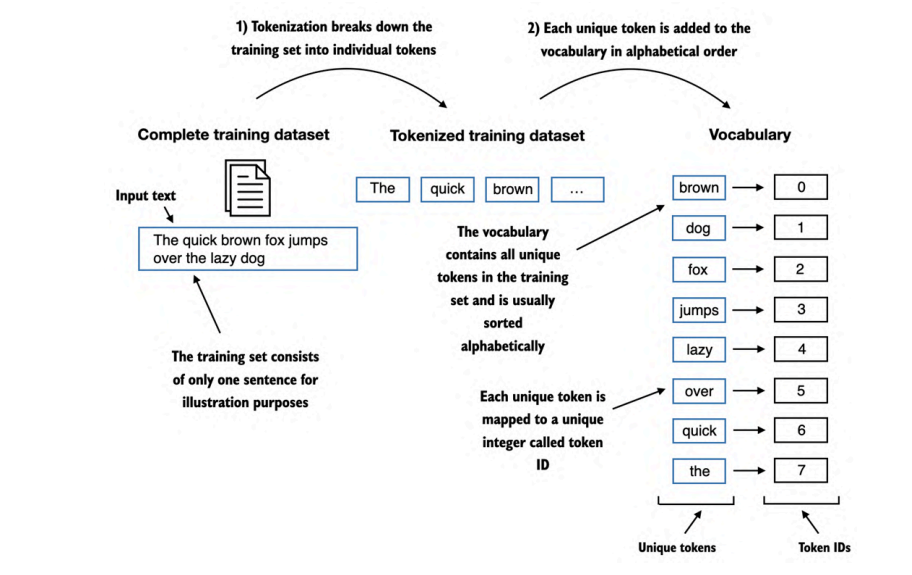

In [52]:
# getting rid of all the duplicates using set and then arrange them in sorted order

all_words = sorted(set(preprocessed))
vocab_size = len(all_words)

print(vocab_size)

1130


In [53]:
vocab = {token: integer for integer, token in enumerate(all_words) }

In [54]:
type(vocab)

dict

In [55]:
for i, item in enumerate(vocab.items()):
    print(item)
    if i >= 50:
        break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


In [56]:
# Creating a simple tokenizer class

class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)

        preprocessed = [item.strip() for item in preprocessed if item.strip()]

        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

In [57]:
tokenizer = SimpleTokenizerV1(vocab)

text = """"It's the last he painted, you know," 
           Mrs. Gisburn said with pardonable pride."""

ids = tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [58]:
tokenizer.decode(ids)

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

In [59]:
tokenizer.decode(tokenizer.encode(text))

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

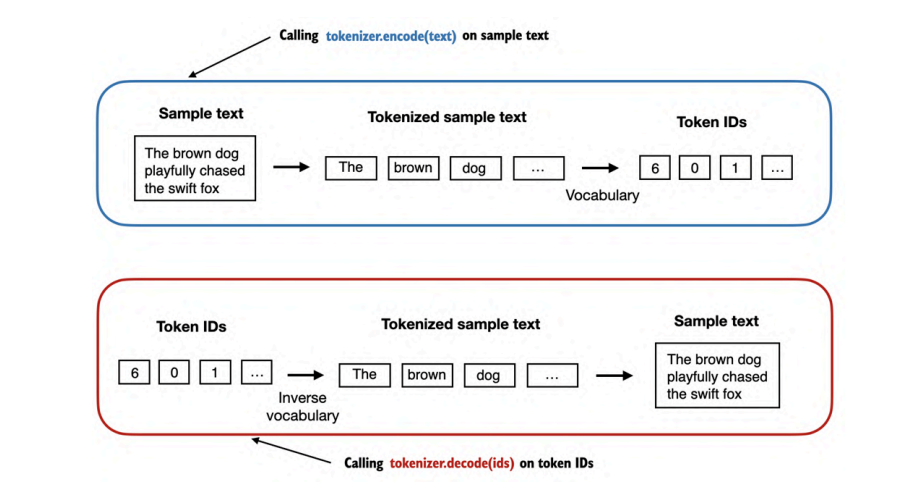

### Adding special context tokens